# An AI assistant and data you have already processed

[07_working_with_an_ai_assistant](07_working_with_an_ai_assistant.ipynb) starts from raw probe
files. This notebook starts from the other end: you already have processed files, made by this
package, by another program, or by someone else. You want an AI coding assistant to help you
look inside them, test a feature of the package against them, check one aspect of their quality,
or read them in a different file format.

**What you will learn**

- a first prompt for "I already have processed files", which keeps those files read-only;
- the questions the assistant must ask you before it opens anything, and why each one matters;
- prompts for four jobs: examining the data, testing a feature or option against your product,
  checking a data-quality aspect, and working with output file formats;
- the package's own tool for each job, and what each tool will and will not do;
- the caveats: a product from other software is compared, never reproduced; where a file came
  from is written down; nothing is overwritten.

**What data:** none. The few code cells print the package's version and the start of two
commands' help, and write the question checklist and a prompt template into a temporary folder.
No probe file is read.

Section 8 compares two small synthetic (demo) data sets built in memory, to show how to look at where two files differ.

**Before this:** [07_working_with_an_ai_assistant](07_working_with_an_ai_assistant.ipynb) (Working with an AI coding assistant). **Next:** [09_ai_assistant_limits_and_ethics](09_ai_assistant_limits_and_ethics.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

## 1. The first prompt

Open a terminal in the root folder of this repository, start your assistant there, and paste
this, with the folder filled in. Its first rule is that your files are only ever read.

```text
I have optical array probe data that has already been processed, in <folder>.
I want to use the arrayprobe package in this folder to look at it. Before you run anything:
1. Treat <folder> as read-only: never write, move, rename or delete anything in it.
   Anything you make goes into a new output folder that we agree on.
2. Read README.md, docs/06-configuration.md and the notebooks in
   examples/1_getting_started/, especially 06_read_products and
   08_ai_assistant_with_your_own_data.
3. Ask me the questions in 08_ai_assistant_with_your_own_data, section 2, one at a
   time, and wait for each answer.
4. Only then list what is in <folder> (file names, sizes, and the time range each file
   covers), without changing anything, and tell me what you think each file is.
Only use commands and options that the documentation or `--help` shows. If you are not
sure a command exists, run it with --help first and tell me what it says.
```

Asking for the listing last is deliberate: a file name rarely says which program wrote it, and
an assistant that guesses will describe the file with confidence either way. The cell below
checks that the package is installed.

In [1]:
# Launch guard: the cells below reach examples/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("examples").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/1_getting_started/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import arrayprobe

print("arrayprobe version:", arrayprobe.__version__)
print("default engine:    ", arrayprobe.engine().name)

arrayprobe version: 0.1.0
default engine:     3.5


## 2. The questions the assistant must ask first

Each answer changes what the assistant may do with the files, so each is a question for you,
never a guess.

| # | Question | Why it is asked |
|---|---|---|
| 1 | Which software wrote these files, and which version? (this package and which engine, UIOOPS and which release, SODA-2, or another program) | It decides which tools apply. `arrayprobe provenance` and `arrayprobe compare` read this package's own files; a file from another program is read as an ordinary netCDF file and compared, never reproduced. |
| 2 | What format are they, and which variables do they hold? (netCDF, Zarr, Parquet, text; a particle-by-particle file or a size distribution) | A particle file and a size distribution answer different questions and are compared differently. |
| 3 | Which probe made them? (2D-S, HVPS, CIP, PIP, 2DC, 2DP or Fast2DC; which channel) | The size bins, the sample area and the data-quality checks that apply depend on the probe. `docs/33-probes.md` has one page per probe. |
| 4 | Where are they, and are the raw probe files available too? | Without the raw files, nothing can be re-processed; the work is limited to reading and comparing. |
| 5 | Are they read-only, and may they be shown to the assistant? | Someone else's product is never modified. Some campaign data are not yet public; keep them out of anything you publish. |
| 6 | What settings made them? (a settings file, a `.call` file, a processing log, a methods paragraph, or unknown) | A comparison can explain a difference only against settings that are known. "Unknown" is an answer; write it down. |
| 7 | What do you want to learn? (look inside; test a feature; check one quality aspect; change the file format) | It picks the section of this notebook, and so the tool. |

Paste this once the first prompt has been answered:

```text
Before you open anything in <folder>, ask me the seven questions in
examples/1_getting_started/08_ai_assistant_with_your_own_data.ipynb, section 2, one
at a time. Write my answers into data_notes.txt in our output folder, with the date.
If I answer "unknown", write "unknown"; do not fill it in from a file name or a guess.
```

The cell below writes the same questions into a plain-text file. It goes into a temporary
folder here; point `folder` at your own project to keep it.

In [2]:
import tempfile

QUESTIONS = [
    "Software and version that wrote the files (this package and engine, UIOPS, SODA-2, other):",
    "File format and variables (particle-by-particle file or size distribution):",
    "Probe and channel:",
    "Where the files are; are the raw probe files available too?:",
    "Read-only? May they be shown to the assistant? Public or not yet?:",
    "Settings that made them (settings file, .call file, log, methods text, or unknown):",
    "What I want to learn (examine; test a feature; a quality aspect; a file format):",
]

folder = Path(tempfile.mkdtemp())
notes = folder / "data_notes.txt"
lines = ["Notes on already-processed data. Fill in every line before anything is opened.", ""]
lines += [f"{i}. {q}\n   answer:" for i, q in enumerate(QUESTIONS, start=1)]
notes.write_text("\n".join(lines) + "\n", encoding="utf-8")

print(f"wrote {notes.name} ({len(QUESTIONS)} questions)\n")
print(notes.read_text(encoding="utf-8"))

wrote data_notes.txt (7 questions)

Notes on already-processed data. Fill in every line before anything is opened.

1. Software and version that wrote the files (this package and engine, UIOPS, SODA-2, other):
   answer:
2. File format and variables (particle-by-particle file or size distribution):
   answer:
3. Probe and channel:
   answer:
4. Where the files are; are the raw probe files available too?:
   answer:
5. Read-only? May they be shown to the assistant? Public or not yet?:
   answer:
6. Settings that made them (settings file, .call file, log, methods text, or unknown):
   answer:
7. What I want to learn (examine; test a feature; a quality aspect; a file format):
   answer:



## 3. Examining the data: what is in the files

```text
Open each file in <folder> read-only (xarray or netCDF4, as
examples/1_getting_started/06_read_products.ipynb does) and, for each one, tell me:
its dimensions; every variable with its units and a one-line meaning; the time range
and how many seconds are missing; and the size bins, if it has any. Where a variable
carries no units attribute, say so; do not supply one from memory.
If any file has a .call file beside it, run `arrayprobe provenance <folder>` and
explain in plain words what each .call file records.
```

The tools for this job, all of which only read:

- [06_read_products](06_read_products.ipynb) opens this package's three kinds of output file
  and explains each variable and the `.call` file beside it. A file from another program is
  opened the same way, but its variables are its own: ask the assistant to read them from the
  file, never to assume they mean what this package's variables of the same name mean.
- `arrayprobe provenance <files or folder>` reports, for each file, which engine, rules and
  stage its `.call` file records. A file with no `.call` file is reported as unstamped, which is
  the true answer for anything this package did not write.
- [06_provenance](../7_analysis_and_outputs/06_provenance.ipynb) reads two products' stamps side
  by side.

The cell below prints the start of the `provenance` help, which is what the assistant should
read before running it.

In [3]:
import subprocess
import sys

result = subprocess.run([sys.executable, "-m", "arrayprobe", "provenance", "--help"],
                        capture_output=True, text=True, check=True)
for line in result.stdout.splitlines()[:9]:
    print(line)
print("...")

usage: arrayprobe provenance [-h] [--require] paths [paths ...]

Per file: the engine, profile and stage its stamp records, the stamp's format,
its link count, and its state -- stamped, unstamped, orphan-stamp (a sidecar
whose product is gone), in-flight, legacy-json or unparseable. A directory
expands to every .nc/.cdf in it plus every orphan sidecar. Nothing here infers
an engine from a date, a filename or a neighbouring file: a product whose
stamp does not name one is reported as unrecorded, which is the true answer.
The git revision printed at the end is THIS CHECKOUT's, not the product's --
...


## 4. Testing a feature or an option against your product

The package's optional corrections are off unless a run's settings file switches each one on.
To see what one would change in your data, the test is always a pair: the same raw files
processed with it off and with it on, each into its own folder, then compared. Your existing
product is the reference for both and is never written to.

**If the raw probe files are available:**

```text
I want to test <feature or option> against my product in <folder>.
1. Show me where docs/05-enhancements.md (or the notebook) describes it, and whether it
   is on or off by default.
2. Write two settings files that differ only in that option. Show me both before you
   run anything, then run each into its own new output folder, never into <folder>.
3. Compare each result with my product, and the two results with each other, using
   the tool the documentation names for files of that kind. Report every difference
   with the seconds and size bins it sits in.
4. Do not change any other setting to make the results agree with my product.
```

**If only the processed files are available:** some extras work on a processed product rather
than on raw files (moments, a two-probe overlap check, a CF-1.10 copy and others).
[08_enhancements_on_a_product](../7_analysis_and_outputs/08_enhancements_on_a_product.ipynb)
runs each one on a product this package wrote. Ask the assistant to say first whether the one
you want accepts a file from another program; if the documentation does not say so, the answer
is no.

The tools:

- [08_opt_ins](../2_processing/08_opt_ins.ipynb) and
  [09_enhancement_ab](../2_processing/09_enhancement_ab.ipynb): the options, and an off/on
  comparison worked through.
- `arrayprobe compare <ours> <reference>`: two particle-by-particle files of this package's
  layout, matched particle for particle and judged against tolerance classes. Its exit status is
  0 only when the comparison is accepted.
- `arrayprobe view second <ours> <theirs> --second <s>`: one second of two size-distribution
  files bin by bin.
- `arrayprobe validate by-condition <ours> --product <reference>`: agreement second by second,
  split by how much cloud the probe was in.
- For a product from a different program, the comparison is a procedure rather than one command:
  [03_comparing_processing_chains_in_db](../7_analysis_and_outputs/03_comparing_processing_chains_in_db.ipynb)
  works through it (a common time axis, a clock-offset check, cloud-leg means, differences in dB).

The cell below prints the first tolerance class `compare` uses, so you can see the kind of
judgement it makes.

In [4]:
import textwrap

result = subprocess.run([sys.executable, "-m", "arrayprobe", "compare", "--classes"],
                        capture_output=True, text=True, check=True)
for line in result.stdout.splitlines()[:2]:
    print(textwrap.fill(line, 100, subsequent_indent="    "))

A  bit-exact  (asserts)
    Integers, ASCII codes, counts and bin edges. Any difference at all is a failure — these carry no
    floating-point slack, so a mismatch is a real disagreement about what happened, never a rounding
    artefact.


## 5. Checking one data-quality aspect

Each common problem in optical array probe data has its own notebook in `5_data_quality/`, built
on synthetic data, with a place to point it at your own file. Pick the row that matches your
question and give the assistant its notebook:

| Your question | Notebook |
|---|---|
| Is a diode stuck on or off? | [01_find_stuck_diodes](../5_data_quality/01_find_stuck_diodes.ipynb) |
| Is the airspeed right, or stuck at one value? | [02_airspeed_and_stuck_airspeed](../5_data_quality/02_airspeed_and_stuck_airspeed.ipynb) |
| Is one file's clock offset from another's? | [03_clock_offsets](../5_data_quality/03_clock_offsets.ipynb) |
| Are some seconds in the file twice? | [06_duplicated_seconds](../5_data_quality/06_duplicated_seconds.ipynb) |
| Are hollow particles mis-sized? | [07_hollow_particles](../5_data_quality/07_hollow_particles.ipynb) |
| Do the inter-arrival times roll over? | [08_interarrival_rollover](../5_data_quality/08_interarrival_rollover.ipynb) |
| Is shattering removed? | [09_shattering_interarrival_fit](../5_data_quality/09_shattering_interarrival_fit.ipynb) |

[`5_data_quality/README.md`](../5_data_quality/README.md) lists every notebook in the track,
and which of them take a file you supply.

```text
I want to check <aspect> in my file <file>. Read
examples/5_data_quality/<notebook> first and tell me in a few sentences what it checks
and what it needs from my file. Then run its steps on my file, reading it only, and
writing any output into our output folder. For each result, tell me what it means and
what it does not mean. If my file lacks a variable the check needs, stop and tell me.
```

A check run on a product shows that something in it looks wrong; it rarely says why. If the
raw files are available, section 4's off/on pair is how to find out which processing step is
responsible.

## 6. Output file formats: what the package reads and writes

What a run of this package writes (`docs/06-configuration.md`, "A run can write three versions of its result"):

| Output | What it is |
|---|---|
| The original product, with its `.call` file | the processing's own output, the file a validation compares; netCDF (classic format from the validation engine, netCDF4 from the default one) |
| The attributed copy (`.attributed.nc`, and on request Zarr and Parquet) | the same values in a self-describing netCDF4 file, with units on every variable, the run record and the checksum of the original |
| The data-provider-format file | the size distribution in the layout another group uses for its processed product |

For conversion:

- `arrayprobe attributed <product>` writes the attributed copy of a product this package wrote,
  beside it, and opens the original read-only. It refuses a product with no `.call` file unless
  told `--accept-unstamped`, and then the copy records that its origin is not established.
- `python -m arrayprobe.ai_ready <file>` checks an attributed netCDF4 file or Zarr store against
  what the attributed export claims, and exits non-zero on a failure.
- [04_output_formats_and_tables](../7_analysis_and_outputs/04_output_formats_and_tables.ipynb)
  writes one product in every format the package offers and opens each one;
  [07_arco_export_tour](../7_analysis_and_outputs/07_arco_export_tour.ipynb) covers the
  analysis-ready copy.
- A file another program wrote is not converted by these tools. An assistant can read it with
  xarray or netCDF4 and write a copy in the format you ask for, in a new folder, carrying the
  original's attributes and a note of the file it came from; check that copy value for value
  against the original before you use it.

```text
I want <file> in <format> for <use>. First tell me whether the package's own tools
(docs/06-configuration.md, the [outputs] keys) can write that from this file, and which one.
If they can, run it into our output folder. If they cannot, write a short script that
reads the original read-only and writes the copy into our output folder, keeping every
attribute and adding the original's file name and checksum. Then compare every variable
of the copy with the original and show me the result.
```

The cell below writes a prompt template with the safety rules from section 7 into the
temporary folder, ready to fill in and paste.

In [5]:
TEMPLATE = """Data: already processed, in {folder} (read-only).
Written by: {software}. Probe: {probe}. Raw files available: {raw}.
What I want: {goal}.
Rules:
- Never write, move, rename or delete anything in {folder}.
- Write only into {output_folder}, and log every command you run in run_log.txt there.
- A product from other software is compared, not reproduced. Report every difference;
  do not change a setting to make two files agree.
- Use only commands that the documentation or --help shows.
"""

prompt_file = folder / "prompt_for_processed_data.txt"
prompt_file.write_text(TEMPLATE, encoding="utf-8")
print(f"wrote {prompt_file.name}\n")
print(TEMPLATE.format(folder="<folder>", software="<software and version>", probe="<probe>",
                      raw="<yes/no>", goal="<examine / test a feature / a quality aspect / a format>",
                      output_folder="<output folder>"))

wrote prompt_for_processed_data.txt

Data: already processed, in <folder> (read-only).
Written by: <software and version>. Probe: <probe>. Raw files available: <yes/no>.
What I want: <examine / test a feature / a quality aspect / a format>.
Rules:
- Never write, move, rename or delete anything in <folder>.
- Write only into <output folder>, and log every command you run in run_log.txt there.
- A product from other software is compared, not reproduced. Report every difference;
  do not change a setting to make two files agree.
- Use only commands that the documentation or --help shows.



## 7. Caveats

- **A product from other software is compared, never reproduced.** An exact match is expected
  only against a product written by the same program with the same settings. Between programs,
  differences are normal and each one needs a reason; the comparison finds them, and you decide
  what they mean.
- **Write down where every file came from.** Folder, software, version, settings, who gave it to
  you and when: `data_notes.txt` from section 2 is the place. A number quoted later is only as
  good as this record.
- **Never overwrite.** Your product and the raw files stay as they are; every output goes into a
  new folder. If the assistant proposes to "fix" a file in place, stop it.
- **A refusal is a question for you.** When a command refuses a file (no `.call` file, a layout it
  does not recognise, a variable it needs but cannot find), the message says why. Do not let the
  assistant get past it by changing a setting you did not choose.

## 8. Compare your team's file with a new run, by eye

Before you ask an assistant why two files differ, look at where they differ. The cells below
make two synthetic (demo) data sets in memory: one stands in for the file your team already
processed, the other for a new run that differs only in the two smallest bins. With real files,
open each with `xr.open_dataset(path)`.

In [6]:
import numpy as np
import xarray as xr

rng = np.random.default_rng(38)
bin_mid_mm = np.geomspace(0.05, 1.5, 20)  # bin centres
bin_width_mm = np.gradient(bin_mid_mm)
time_s = np.arange(60)  # one minute at one value per second
mean_conc = 400 * np.exp(-bin_mid_mm / 0.25)  # a spectrum falling with size
conc = rng.poisson(mean_conc, size=(time_s.size, bin_mid_mm.size)).astype(float)

ds = xr.Dataset(
    {"conc": (("time", "bin"), conc,
              {"units": "L-1 mm-1", "long_name": "concentration per unit bin width"})},
    coords={"time": ("time", time_s, {"units": "s"}),
            "bin_mid": ("bin", bin_mid_mm, {"units": "mm"})},
    attrs={"note": "synthetic demo data, not a measurement"},
)
team = ds
new = team.copy(deep=True)
new["conc"][:, :2] *= 0.6  # the demo's only difference: the two smallest bins
new

<xarray.Dataset> Size: 10kB
Dimensions:  (time: 60, bin: 20)
Coordinates:
  * time     (time) int64 480B 0 1 2 3 4 5 6 7 8 ... 51 52 53 54 55 56 57 58 59
    bin_mid  (bin) float64 160B 0.05 0.0598 0.07152 0.08555 ... 1.049 1.254 1.5
Dimensions without coordinates: bin
Data variables:
    conc     (time, bin) float64 10kB 196.2 196.2 333.0 303.0 ... 4.0 3.0 0.0
Attributes:
    note:     synthetic demo data, not a measurement

Both files have the same dimensions and the same `units`, so they can be compared bin by
bin. Check this first with real files: two products in different units, or on different bins,
differ for that reason alone.

The ratio of the two mean spectra is a DataArray, one value per bin:

In [7]:
ratio = new["conc"].mean("time") / team["conc"].mean("time")
ratio.attrs = {"units": "1", "long_name": "ratio of mean concentrations, new / team"}
ratio

<xarray.DataArray 'conc' (bin: 20)> Size: 160B
array([0.6, 0.6, 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. ,
       1. , 1. , 1. , 1. , 1. , 1. , 1. ])
Coordinates:
    bin_mid  (bin) float64 160B 0.05 0.0598 0.07152 0.08555 ... 1.049 1.254 1.5
Dimensions without coordinates: bin
Attributes:
    units:      1
    long_name:  ratio of mean concentrations, new / team

The next cell plots the two mean spectra on the same axes.

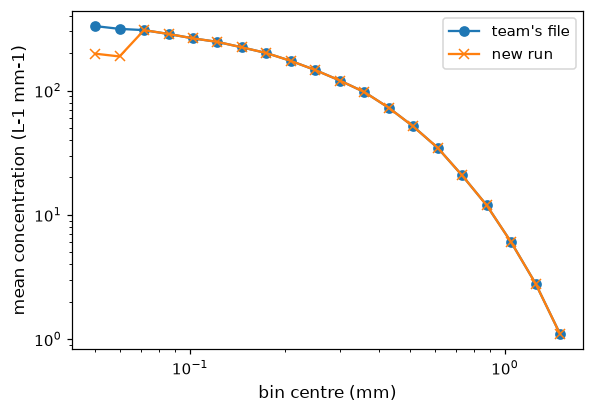

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(team["bin_mid"], team["conc"].mean("time"), marker="o", label="team's file")
ax.plot(new["bin_mid"], new["conc"].mean("time"), marker="x", label="new run")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("bin centre (mm)")
ax.set_ylabel("mean concentration (L-1 mm-1)")
ax.legend()
plt.show()

On a log axis the two spectra look almost the same. A ratio shows the difference
plainly, so the next cell plots it bin by bin.

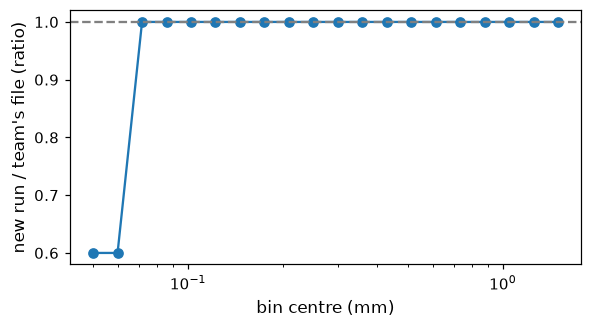

In [9]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(ratio["bin_mid"], ratio, marker="o")
ax.axhline(1.0, color="grey", linestyle="--")
ax.set_xscale("log")
ax.set_xlabel("bin centre (mm)")
ax.set_ylabel("new run / team's file (ratio)")
plt.show()

The ratio is one everywhere except the two smallest bins. A difference confined to a few
bins points at a setting that acts on those sizes; a difference spread over every bin points at
something global, such as a sample volume or a time base. Give the assistant this figure and
ask which settings differ, read from each file's own record, before it changes anything.

## What to try next

- [09_ai_assistant_limits_and_ethics](09_ai_assistant_limits_and_ethics.ipynb): the next
  notebook: responsibility, ethics, and what not to rely on an assistant for.
- [01_validate_against_a_product](../3_validation/01_validate_against_a_product.ipynb):
  comparing a product with a reference, on demo data and then on your own two files.
- [03_comparing_processing_chains_in_db](../7_analysis_and_outputs/03_comparing_processing_chains_in_db.ipynb):
  comparing two programs' products of the same cloud.
- `5_data_quality/`: the checks to run on a product before quoting a number.
- [04_output_formats_and_tables](../7_analysis_and_outputs/04_output_formats_and_tables.ipynb):
  every output format, opened.